In [1]:

from pathlib import Path

import numpy as np
import pandas as pd
import joblib

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_val_predict,
    cross_val_score,
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    precision_recall_curve,
)

RANDOM_STATE = 42
TARGET = "Churn"

project_dir = Path.cwd().resolve()
if not (project_dir / "data").is_dir() and (project_dir.parent / "data").is_dir():
    project_dir = project_dir.parent

DATA_DIR = project_dir / "data"
MODEL_DIR = project_dir / "models"
REPORT_DIR = project_dir / "reports"

for output_dir in (MODEL_DIR, REPORT_DIR):
    output_dir.mkdir(parents=True, exist_ok=True)

print("Imports and project paths initialized.")

Imports and project paths initialized.


In [2]:
data_path = DATA_DIR / "WA_Fn-UseC_-Telco-Customer-Churn.csv"
df = pd.read_csv(data_path)

print(data_path, df.shape)

display(df.head())

print("\nDataset information:")
df.info()

print("\nMissing values:")
display(df.isnull().sum())

print("\nChurn distribution:")
display(df[TARGET].value_counts())

print("\nChurn percentage:")
display(
    (df[TARGET].value_counts(normalize=True) * 100).round(2)
)

C:\Users\KIIT\Desktop\RetailMind\data\WA_Fn-UseC_-Telco-Customer-Churn.csv (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes



Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


Churn distribution:


Churn
No     5174
Yes    1869
Name: count, dtype: int64


Churn percentage:


Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64

In [3]:
# Convert TotalCharges into numeric format.
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce",
)

# Remove customer identifier.
df = df.drop(
    columns=["customerID"],
    errors="ignore",
)

# Encode target.
df[TARGET] = df[TARGET].map({
    "No": 0,
    "Yes": 1,
})

if df[TARGET].isna().any():
    raise ValueError("Unexpected values found in Churn.")

X = df.drop(columns=[TARGET])
y = df[TARGET].astype(int)

print("Features:", X.shape)
print("Target:", y.shape)

print("\nMissing values after conversion:")
display(X.isnull().sum()[X.isnull().sum() > 0])

Features: (7043, 19)
Target: (7043,)

Missing values after conversion:


TotalCharges    11
dtype: int64

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y,
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining churn rate:", round(y_train.mean(), 3))
print("Testing churn rate:", round(y_test.mean(), 3))

Training features: (5634, 19)
Testing features: (1409, 19)

Training churn rate: 0.265
Testing churn rate: 0.265


In [5]:
def make_preprocessor(input_frame):

    numeric_columns = (
        input_frame
        .select_dtypes(include="number")
        .columns
        .tolist()
    )

    categorical_columns = (
        input_frame
        .select_dtypes(exclude="number")
        .columns
        .tolist()
    )

    numeric_pipeline = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ])

    categorical_pipeline = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False,
            ),
        ),
    ])

    preprocessor = ColumnTransformer(
        transformers=[
            (
                "numeric",
                numeric_pipeline,
                numeric_columns,
            ),
            (
                "categorical",
                categorical_pipeline,
                categorical_columns,
            ),
        ]
    )

    return preprocessor


def make_model_pipeline(input_frame, estimator):

    return Pipeline(steps=[
        ("preprocess", make_preprocessor(input_frame)),
        ("model", estimator),
    ])


print("Preprocessing functions created.")

Preprocessing functions created.


In [6]:
lr_options = {
    "Unweighted": None,
    "Balanced": "balanced",
}

cv_strategy_day1 = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE,
)

day1_trials = {}

for option_name, weight in lr_options.items():

    print("Testing:", option_name)

    candidate = make_model_pipeline(
        X_train,
        LogisticRegression(
            max_iter=2000,
            class_weight=weight,
            random_state=RANDOM_STATE,
        ),
    )

    # Out-of-fold probabilities from training data.
    oof_probabilities = cross_val_predict(
        candidate,
        X_train,
        y_train,
        cv=cv_strategy_day1,
        method="predict_proba",
        n_jobs=-1,
    )[:, 1]

    # Calculate precision and recall at different thresholds.
    precisions, recalls, thresholds = precision_recall_curve(
        y_train,
        oof_probabilities,
    )

    # Calculate F1 for each available threshold.
    f1_scores = (
        2 * precisions[:-1] * recalls[:-1]
        / (
            precisions[:-1]
            + recalls[:-1]
            + 1e-10
        )
    )

    best_index = np.argmax(f1_scores)

    day1_trials[option_name] = {
        "weight": weight,
        "threshold": thresholds[best_index],
        "precision": precisions[best_index],
        "recall": recalls[best_index],
        "f1": f1_scores[best_index],
    }

print("\nCross-validation results:")

display(
    pd.DataFrame(day1_trials).T
)

Testing: Unweighted


Testing: Balanced



Cross-validation results:


,weight,threshold,precision,recall,f1
Unweighted,NaN,0.330384,0.560568,0.739799,0.637832
Balanced,balanced,0.574173,0.557837,0.745151,0.63803


In [7]:
best_option = max(
    day1_trials,
    key=lambda name: day1_trials[name]["f1"],
)

best_config = day1_trials[best_option]

baseline_threshold = float(
    best_config["threshold"]
)

print("Selected configuration:", best_option)

print(
    "Selected threshold:",
    round(baseline_threshold, 4),
)

print(
    "Validation precision:",
    round(best_config["precision"], 4),
)

print(
    "Validation recall:",
    round(best_config["recall"], 4),
)

print(
    "Validation F1:",
    round(best_config["f1"], 4),
)

Selected configuration: Balanced
Selected threshold: 0.5742
Validation precision: 0.5578
Validation recall: 0.7452
Validation F1: 0.638


In [8]:
baseline_pipeline = make_model_pipeline(
    X_train,
    LogisticRegression(
        max_iter=2000,
        class_weight=best_config["weight"],
        random_state=RANDOM_STATE,
    ),
)

baseline_pipeline.fit(
    X_train,
    y_train,
)

print("Improved Day 1 Logistic Regression fitted.")

Improved Day 1 Logistic Regression fitted.


In [9]:
# Predict probabilities.
test_probabilities = baseline_pipeline.predict_proba(
    X_test
)[:, 1]

# Apply selected threshold.
test_predictions = (
    test_probabilities >= baseline_threshold
).astype(int)

# Calculate metrics.
day1_metrics = {
    "Model": "Day 1 Logistic Regression",
    "Accuracy": accuracy_score(
        y_test,
        test_predictions,
    ),
    "Precision": precision_score(
        y_test,
        test_predictions,
        zero_division=0,
    ),
    "Recall": recall_score(
        y_test,
        test_predictions,
        zero_division=0,
    ),
    "F1": f1_score(
        y_test,
        test_predictions,
        zero_division=0,
    ),
    "ROC_AUC": roc_auc_score(
        y_test,
        test_probabilities,
    ),
}

display(
    pd.DataFrame([day1_metrics]).set_index("Model")
)

print("\nClassification Report:")

print(
    classification_report(
        y_test,
        test_predictions,
        target_names=["No Churn", "Churn"],
        zero_division=0,
    )
)

print("\nConfusion Matrix:")

print(
    confusion_matrix(
        y_test,
        test_predictions,
    )
)

,Accuracy,Precision,Recall,F1,ROC_AUC
Model,,,,,
Day 1 Logistic Regression,0.762243,0.538767,0.724599,0.618016,0.841298



Classification Report:
              precision    recall  f1-score   support

    No Churn       0.89      0.78      0.83      1035
       Churn       0.54      0.72      0.62       374

    accuracy                           0.76      1409
   macro avg       0.71      0.75      0.72      1409
weighted avg       0.79      0.76      0.77      1409


Confusion Matrix:
[[803 232]
 [103 271]]


In [10]:
day1_model_path = (
    MODEL_DIR / "churn_day1_baseline.joblib"
)

day1_artifact = {
    "pipeline": baseline_pipeline,
    "threshold": baseline_threshold,
    "model_name": "Logistic Regression",
    "positive_class": 1,
}

joblib.dump(
    day1_artifact,
    day1_model_path,
)

print("Day 1 model saved:", day1_model_path)

Day 1 model saved: C:\Users\KIIT\Desktop\RetailMind\models\churn_day1_baseline.joblib


In [11]:
def predict_churn(customer_rows, artifact=None):

    if artifact is None:
        artifact = day1_artifact

    fitted_model = artifact["pipeline"]
    threshold = artifact["threshold"]

    probabilities = fitted_model.predict_proba(
        customer_rows
    )[:, 1]

    labels = (
        probabilities >= threshold
    ).astype(int)

    return pd.DataFrame(
        {
            "predicted_churn": labels,
            "churn_probability": probabilities,
        },
        index=customer_rows.index,
    )


display(
    predict_churn(X_test.head())
)

,predicted_churn,churn_probability
437,0,0.115472
2280,1,0.853079
2235,0,0.146831
4460,1,0.660663
3761,0,0.060436


In [12]:
day1_report_path = (
    REPORT_DIR / "day1_baseline_metrics.csv"
)

pd.DataFrame([day1_metrics]).to_csv(
    day1_report_path,
    index=False,
)

print("Metrics saved:", day1_report_path)

Metrics saved: C:\Users\KIIT\Desktop\RetailMind\reports\day1_baseline_metrics.csv


# Day 2 — Compare Candidate Models

Goal: Compare Decision Tree, Random Forest, and SVM
against the Day 1 Logistic Regression baseline.

Selection metric: Churn Recall.

In [13]:
day2_candidates = {
    "Decision Tree": DecisionTreeClassifier(
        random_state=RANDOM_STATE,
        class_weight="balanced"
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=250,
        random_state=RANDOM_STATE,
        class_weight="balanced",
        n_jobs=-1
    ),

    "SVM": SVC(
        kernel="rbf",
        probability=True,
        class_weight="balanced",
        random_state=RANDOM_STATE
    )
}

print("Candidate models:", list(day2_candidates.keys()))

Candidate models: ['Decision Tree', 'Random Forest', 'SVM']


In [14]:
cv_strategy = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=RANDOM_STATE
)

day2_fitted = {}
day2_rows = []

for model_name, estimator in day2_candidates.items():

    candidate_pipeline = make_model_pipeline(
        X_train,
        estimator
    )

    # Calculate cross-validation recall using training data
    cv_recall = cross_val_score(
        candidate_pipeline,
        X_train,
        y_train,
        scoring="recall",
        cv=cv_strategy,
        n_jobs=-1
    ).mean()

    # Train on the complete training dataset
    candidate_pipeline.fit(X_train, y_train)

    day2_fitted[model_name] = candidate_pipeline

    # Evaluate on the untouched test dataset
    predictions = candidate_pipeline.predict(X_test)
    probabilities = candidate_pipeline.predict_proba(X_test)[:, 1]

    metrics = {
        "Model": model_name,
        "CV_Recall": cv_recall,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1": f1_score(y_test, predictions, zero_division=0),
        "ROC_AUC": roc_auc_score(y_test, probabilities)
    }

    day2_rows.append(metrics)

day2_comparison = pd.DataFrame(day2_rows)

day2_comparison = day2_comparison.sort_values(
    by="CV_Recall",
    ascending=False
)

display(day2_comparison)

C:\Users\KIIT\Desktop\RetailMind\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


,Model,CV_Recall,Accuracy,Precision,Recall,F1,ROC_AUC
2,SVM,0.779253,0.743790,0.511504,0.772727,0.615548,0.821065
1,Random Forest,0.632116,0.767211,0.554245,0.628342,0.588972,0.822399
0,Decision Tree,0.490970,0.731725,0.494565,0.486631,0.490566,0.653696


In [15]:
day2_comparison.to_csv(
    REPORT_DIR / "day2_model_comparison.csv",
    index=False
)

print("Day 2 comparison report saved successfully.")

Day 2 comparison report saved successfully.


In [16]:
day2_champion_name = day2_comparison.iloc[0]["Model"]

day2_champion = day2_fitted[day2_champion_name]

print("Day 2 Champion:", day2_champion_name)

print("Selection basis: Highest cross-validation recall.")

Day 2 Champion: SVM
Selection basis: Highest cross-validation recall.


In [17]:
champion_predictions = day2_champion.predict(X_test)

print("Classification Report:")
print(
    classification_report(
        y_test,
        champion_predictions,
        target_names=["No Churn", "Churn"]
    )
)

print("Confusion Matrix:")
print(confusion_matrix(y_test, champion_predictions))

Classification Report:
              precision    recall  f1-score   support

    No Churn       0.90      0.73      0.81      1035
       Churn       0.51      0.77      0.62       374

    accuracy                           0.74      1409
   macro avg       0.71      0.75      0.71      1409
weighted avg       0.80      0.74      0.76      1409

Confusion Matrix:
[[759 276]
 [ 85 289]]


In [18]:
day2_champion_path = MODEL_DIR / "churn_day2_champion.joblib"

joblib.dump(
    day2_champion,
    day2_champion_path
)

print("Champion saved at:", day2_champion_path)

Champion saved at: C:\Users\KIIT\Desktop\RetailMind\models\churn_day2_champion.joblib


# Day 3 — Hyperparameter tuning and generalisation


In [19]:
day3_search_spaces = {
    "Decision Tree": (
        DecisionTreeClassifier(
            random_state=RANDOM_STATE,
            class_weight="balanced"
        ),
        {
            "model__max_depth": [4, 8, None],
            "model__min_samples_leaf": [1, 5],
        },
    ),

    "Random Forest": (
        RandomForestClassifier(
            random_state=RANDOM_STATE,
            class_weight="balanced",
            n_jobs=-1,
        ),
        {
            "model__n_estimators": [150, 250],
            "model__max_depth": [None, 10],
            "model__min_samples_leaf": [1, 3],
        },
    ),

    "SVM": (
        SVC(
            kernel="rbf",
            probability=True,
            class_weight="balanced"
        ),
        {
            "model__C": [0.5, 1, 3],
            "model__gamma": ["scale", "auto"],
        },
    ),
}

print("Search spaces defined.")

Search spaces defined.


# Day 5 — Deep Learning: ANN Customer-Propensity Model

Introduce deep learning without abandoning the discipline of benchmarking.

This increment:

1. Warms up on the Keras **MNIST** demo to make layers, activations and the training loop concrete.
2. Builds a small feed-forward **ANN** for Telco churn: normalised inputs → dense layers → sigmoid output.
3. Trains with **early stopping** on a held-out validation split so we can see overfitting as it happens.
4. Benchmarks the ANN head-to-head against the **Day 4 classical champion** on the untouched test set.
5. Saves the model and records an honest "when to use which" conclusion.

The comparison is deliberately fair: the ANN uses the **same train/test split, the same engineered features and the same 30 selected features** as the Day 4 champion. Only the estimator family changes.

## Part A — MNIST warm-up (Keras fundamentals)

MNIST is a 10-class image problem, not churn, but it exposes every moving part of a Keras workflow:

- **Input shape** — each 28×28 image is flattened to 784 pixels.
- **Dense layers** — learn weighted sums of inputs.
- **ReLU** — keeps the network non-linear without saturating.
- **Softmax** — turns 10 logits into a probability distribution.
- **Loss + optimiser** — `sparse_categorical_crossentropy` + Adam.
- **Training loop** — `fit()` performs forward pass, loss, backpropagation and weight update per mini-batch.

We use a 20,000-image subset and 3 epochs so the warm-up stays fast; the point is mechanics, not a record score.

In [20]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.datasets import mnist

(x_train_mnist, y_train_mnist), (x_test_mnist, y_test_mnist) = mnist.load_data()

# Pixel values are 0-255; neural networks train better on 0-1 inputs.
x_train_mnist = x_train_mnist.astype("float32") / 255.0
x_test_mnist = x_test_mnist.astype("float32") / 255.0

# Small subset keeps the teaching warm-up quick.
warmup_size = 20_000
x_warm_train = x_train_mnist[:warmup_size]
y_warm_train = y_train_mnist[:warmup_size]

mnist_model = keras.Sequential(
    [
        keras.Input(shape=(28, 28), name="image"),
        layers.Flatten(name="flatten"),
        layers.Dense(128, activation="relu", name="hidden"),
        layers.Dropout(0.2, name="dropout"),
        layers.Dense(10, activation="softmax", name="digits"),
    ],
    name="mnist_mlp",
)

mnist_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

mnist_model.summary()

mnist_history = mnist_model.fit(
    x_warm_train,
    y_warm_train,
    epochs=3,
    batch_size=128,
    validation_split=0.1,
    verbose=0,
)

mnist_test_loss, mnist_test_accuracy = mnist_model.evaluate(
    x_test_mnist,
    y_test_mnist,
    verbose=0,
)

print(f"\nMNIST test accuracy: {mnist_test_accuracy:.4f}")
print(f"MNIST test loss:     {mnist_test_loss:.4f}")

mnist_sample_probabilities = mnist_model.predict(
    x_test_mnist[:5],
    verbose=0,
)

print("\nSample predictions vs actual:")
for index, probabilities in enumerate(mnist_sample_probabilities):
    print(
        f"  image {index}: predicted={int(np.argmax(probabilities))} "
        f"(confidence={probabilities.max():.3f}), actual={int(y_test_mnist[index])}"
    )

Model: "mnist_mlp"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden (Dense)                  │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ digits (Dense)                  │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)


MNIST test accuracy: 0.9406
MNIST test loss:     0.2086

Sample predictions vs actual:
  image 0: predicted=7 (confidence=0.994), actual=7
  image 1: predicted=2 (confidence=0.931), actual=2
  image 2: predicted=1 (confidence=0.974), actual=1
  image 3: predicted=0 (confidence=0.999), actual=0
  image 4: predicted=4 (confidence=0.947), actual=4


## Part B — Telco churn ANN

### Design choices

- **Problem type:** binary classification, so the output layer is one unit with a **sigmoid**.
- **Loss:** `binary_crossentropy`, the natural loss for a Bernoulli target.
- **Inputs:** the Day 4 engineered features, median-imputed, standard-scaled and one-hot encoded, then reduced to the same 30 features used by the classical champion.
- **Regularisation:** dropout plus early stopping on `val_loss` (weights restored from the best epoch).
- **Class imbalance:** balanced class weights, consistent with the recall-first objective used in earlier days.
- **Decision threshold:** selected on the validation split by maximising F1, never on the test set.

Three depths are compared so "does depth help?" is answered with evidence rather than intuition.

In [21]:
import random

import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)

# Reproducibility for Python and TensorFlow/Keras.
keras.utils.set_random_seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
random.seed(RANDOM_STATE)

print("TensorFlow:", tf.__version__)
print("Keras:", keras.__version__)


def add_day4_features(input_frame):
    """Recreate the feature engineering used by the Day 4 champion."""
    engineered = input_frame.copy()

    engineered["average_charge_per_month"] = (
        engineered["TotalCharges"]
        / engineered["tenure"].replace(0, np.nan)
    )
    engineered["is_month_to_month"] = (
        engineered["Contract"] == "Month-to-month"
    ).astype(int)
    engineered["uses_electronic_check"] = (
        engineered["PaymentMethod"] == "Electronic check"
    ).astype(int)
    engineered["tenure_group"] = pd.cut(
        engineered["tenure"],
        bins=[-1, 12, 24, 48, 72],
        labels=["0-12", "13-24", "25-48", "49-72"],
    )

    return engineered


X_train_engineered = add_day4_features(X_train)
X_test_engineered = add_day4_features(X_test)

day4_champion = joblib.load(
    MODEL_DIR / "churn_day4_champion.joblib"
)

# Sanity check: the loaded champion must reproduce its Day 4 test metrics.
day4_test_probabilities = day4_champion.predict_proba(
    X_test_engineered
)[:, 1]
day4_test_predictions = (
    day4_test_probabilities >= 0.5
).astype(int)

day4_metrics = {
    "Model": "Day 4 - Classical Champion (Random Forest)",
    "Accuracy": accuracy_score(y_test, day4_test_predictions),
    "Precision": precision_score(y_test, day4_test_predictions, zero_division=0),
    "Recall": recall_score(y_test, day4_test_predictions, zero_division=0),
    "F1": f1_score(y_test, day4_test_predictions, zero_division=0),
    "ROC_AUC": roc_auc_score(y_test, day4_test_probabilities),
}

print("Day 4 champion sanity check on the test set:")
display(pd.DataFrame([day4_metrics]).set_index("Model"))

TensorFlow: 2.21.0
Keras: 3.15.1


Day 4 champion sanity check on the test set:


,Accuracy,Precision,Recall,F1,ROC_AUC
Model,,,,,
Day 4 - Classical Champion (Random Forest),0.753016,0.527311,0.671123,0.590588,0.823823


In [22]:
# Fit preprocessing on the training split only, then apply it to test.
ann_preprocessor = make_preprocessor(X_train_engineered)

X_train_prepared = ann_preprocessor.fit_transform(X_train_engineered)
X_test_prepared = ann_preprocessor.transform(X_test_engineered)

# Mirror the champion's SelectKBest(k=30) so the estimator is the only difference.
ann_selector = SelectKBest(
    score_func=f_classif,
    k=30,
).fit(X_train_prepared, y_train)

X_train_selected = ann_selector.transform(X_train_prepared)
X_test_selected = ann_selector.transform(X_test_prepared)

ANN_INPUT_DIM = X_train_selected.shape[1]

print("Prepared training matrix:", X_train_prepared.shape)
print("Selected training matrix:", X_train_selected.shape)
print("Selected test matrix:    ", X_test_selected.shape)

# A stratified validation split is used for early stopping and threshold selection.
X_ann_train, X_ann_val, y_ann_train, y_ann_val = train_test_split(
    X_train_selected,
    y_train,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y_train,
)

ann_class_weights = dict(
    enumerate(
        compute_class_weight(
            class_weight="balanced",
            classes=np.unique(y_ann_train),
            y=y_ann_train,
        )
    )
)

print("\nANN training rows:", X_ann_train.shape[0])
print("ANN validation rows:", X_ann_val.shape[0])
print("Class weights:", ann_class_weights)

Prepared training matrix: (5634, 52)
Selected training matrix: (5634, 30)
Selected test matrix:     (1409, 30)

ANN training rows: 4507
ANN validation rows: 1127
Class weights: {0: np.float64(0.6806100875868317), 1: np.float64(1.8841973244147157)}


### Train three ANN depths with early stopping

All variants share the same inputs, loss, optimiser and validation split. The only change is depth/width. Early stopping monitors validation loss, restores the best weights, and `ReduceLROnPlateau` lowers the learning rate when validation loss stalls.

In [23]:
def build_churn_ann(
    input_dim,
    hidden_units,
    dropout_rates,
    learning_rate=1e-3,
):
    model = keras.Sequential(name="retailmind_churn_ann")
    model.add(keras.Input(shape=(input_dim,), name="customer_features"))

    for layer_index, (units, dropout_rate) in enumerate(
        zip(hidden_units, dropout_rates),
        start=1,
    ):
        model.add(
            layers.Dense(
                units,
                activation="relu",
                name=f"dense_{layer_index}",
            )
        )
        model.add(
            layers.Dropout(
                dropout_rate,
                name=f"dropout_{layer_index}",
            )
        )

    # One sigmoid unit outputs P(churn = 1).
    model.add(layers.Dense(1, activation="sigmoid", name="churn_probability"))

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
        loss="binary_crossentropy",
        metrics=[
            keras.metrics.BinaryAccuracy(name="accuracy"),
            keras.metrics.AUC(name="auc"),
            keras.metrics.Recall(name="recall"),
        ],
    )
    return model


ann_configs = {
    "ANN - Small (1 x 32)": {
        "hidden_units": (32,),
        "dropout_rates": (0.2,),
    },
    "ANN - Medium (2 x 64-32)": {
        "hidden_units": (64, 32),
        "dropout_rates": (0.3, 0.2),
    },
    "ANN - Deep (3 x 128-64-32)": {
        "hidden_units": (128, 64, 32),
        "dropout_rates": (0.4, 0.3, 0.2),
    },
}

ann_models = {}
ann_histories = {}
ann_thresholds = {}
ann_experiment_rows = []

for model_name, config in ann_configs.items():
    print(f"Training {model_name} ...")

    keras.utils.set_random_seed(RANDOM_STATE)

    model = build_churn_ann(
        input_dim=ANN_INPUT_DIM,
        **config,
    )

    callbacks = [
        keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=12,
            restore_best_weights=True,
            verbose=0,
        ),
        keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.5,
            patience=5,
            min_lr=1e-5,
            verbose=0,
        ),
    ]

    history = model.fit(
        X_ann_train,
        y_ann_train,
        validation_data=(X_ann_val, y_ann_val),
        epochs=150,
        batch_size=64,
        class_weight=ann_class_weights,
        callbacks=callbacks,
        verbose=0,
    )

    validation_probabilities = model.predict(
        X_ann_val,
        verbose=0,
    ).ravel()

    # Choose the F1-optimal threshold on validation only.
    precisions, recalls, thresholds = precision_recall_curve(
        y_ann_val,
        validation_probabilities,
    )
    f1_scores = (
        2 * precisions[:-1] * recalls[:-1]
        / (precisions[:-1] + recalls[:-1] + 1e-10)
    )
    best_index = int(np.argmax(f1_scores))
    validation_threshold = float(thresholds[best_index])

    validation_predictions = (
        validation_probabilities >= validation_threshold
    ).astype(int)

    ann_models[model_name] = model
    ann_histories[model_name] = history
    ann_thresholds[model_name] = validation_threshold

    ann_experiment_rows.append(
        {
            "Model": model_name,
            "Hidden Layers": len(config["hidden_units"]),
            "Validation Accuracy": accuracy_score(
                y_ann_val,
                validation_predictions,
            ),
            "Validation Recall": recall_score(
                y_ann_val,
                validation_predictions,
                zero_division=0,
            ),
            "Validation F1": f1_score(
                y_ann_val,
                validation_predictions,
                zero_division=0,
            ),
            "Validation AUC": roc_auc_score(
                y_ann_val,
                validation_probabilities,
            ),
            "Best Epoch": len(history.history["loss"]),
            "Threshold": validation_threshold,
        }
    )

ann_experiments = (
    pd.DataFrame(ann_experiment_rows)
    .sort_values("Validation AUC", ascending=False)
    .reset_index(drop=True)
)

print("\nANN depth comparison (validation split):")
display(ann_experiments)

ann_experiments.to_csv(
    REPORT_DIR / "day5_ann_experiments.csv",
    index=False,
)

Training ANN - Small (1 x 32) ...


Training ANN - Medium (2 x 64-32) ...


Training ANN - Deep (3 x 128-64-32) ...



ANN depth comparison (validation split):


,Model,Hidden Layers,Validation Accuracy,Validation Recall,Validation F1,Validation AUC,Best Epoch,Threshold
0,ANN - Small (1 x 32),1,0.818101,0.648829,0.654300,0.846903,48,0.669388
1,ANN - Deep (3 x 128-64-32),3,0.822538,0.665552,0.665552,0.846132,32,0.639471
2,ANN - Medium (2 x 64-32),2,0.822538,0.655518,0.662162,0.845546,39,0.678808


Selected architecture: ANN - Small (1 x 32)
Validation-selected threshold: 0.6694

Head-to-head on the untouched test set:


,Accuracy,Precision,Recall,F1,ROC_AUC
Model,,,,,
Day 4 - Classical Champion (Random Forest),0.7530,0.5273,0.6711,0.5906,0.8238
Day 5 - ANN - Small (1 x 32),0.7828,0.5895,0.5989,0.5942,0.8376



ANN classification report:
              precision    recall  f1-score   support

    No Churn       0.85      0.85      0.85      1035
       Churn       0.59      0.60      0.59       374

    accuracy                           0.78      1409
   macro avg       0.72      0.72      0.72      1409
weighted avg       0.78      0.78      0.78      1409

ANN confusion matrix:
[[879 156]
 [150 224]]


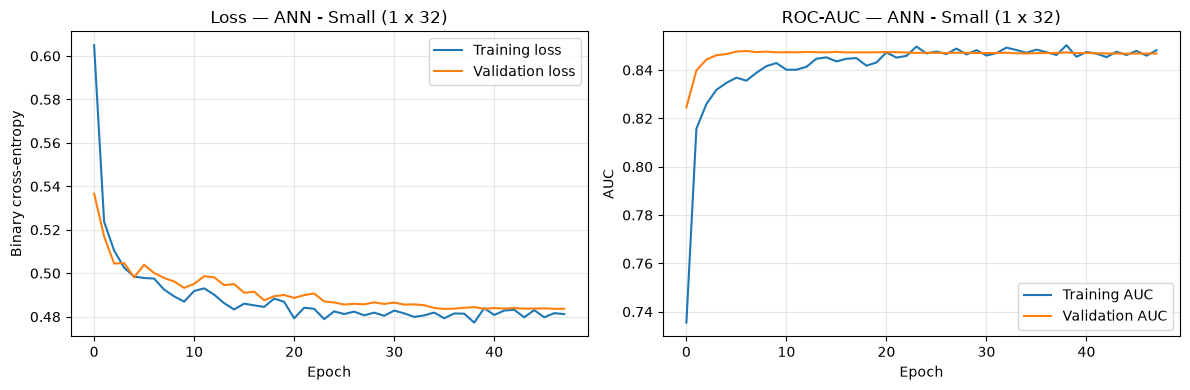

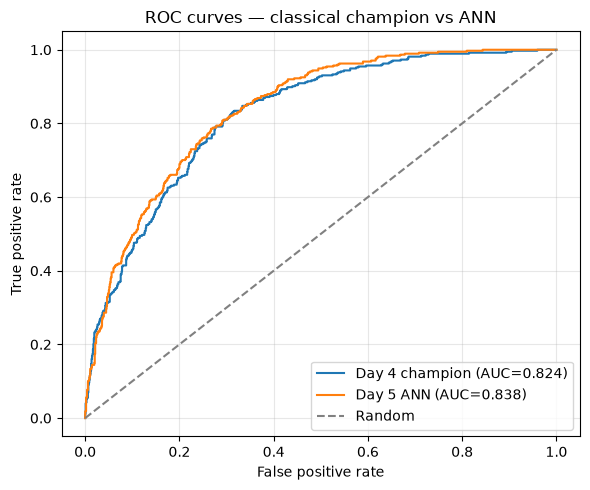


Conclusion signals (ANN minus classical champion):
  Recall delta:  -0.0722
  F1 delta:      +0.0036
  ROC-AUC delta: +0.0137


In [24]:
# Select the strongest architecture by validation ROC-AUC (threshold-independent).
best_ann_name = ann_experiments.iloc[0]["Model"]
best_ann = ann_models[best_ann_name]
best_ann_threshold = ann_thresholds[best_ann_name]
best_ann_history = ann_histories[best_ann_name]

test_probabilities = best_ann.predict(
    X_test_selected,
    verbose=0,
).ravel()
test_predictions = (
    test_probabilities >= best_ann_threshold
).astype(int)

ann_metrics = {
    "Model": f"Day 5 - {best_ann_name}",
    "Accuracy": accuracy_score(y_test, test_predictions),
    "Precision": precision_score(y_test, test_predictions, zero_division=0),
    "Recall": recall_score(y_test, test_predictions, zero_division=0),
    "F1": f1_score(y_test, test_predictions, zero_division=0),
    "ROC_AUC": roc_auc_score(y_test, test_probabilities),
}

day5_comparison = pd.DataFrame(
    [day4_metrics, ann_metrics]
).set_index("Model")

print(f"Selected architecture: {best_ann_name}")
print(f"Validation-selected threshold: {best_ann_threshold:.4f}")

print("\nHead-to-head on the untouched test set:")
display(day5_comparison.round(4))

print("\nANN classification report:")
print(
    classification_report(
        y_test,
        test_predictions,
        target_names=["No Churn", "Churn"],
        zero_division=0,
    )
)

print("ANN confusion matrix:")
print(confusion_matrix(y_test, test_predictions))

day5_comparison.to_csv(
    REPORT_DIR / "day5_ann_comparison.csv"
)

# --- Training curves -------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(
    best_ann_history.history["loss"],
    label="Training loss",
)
axes[0].plot(
    best_ann_history.history["val_loss"],
    label="Validation loss",
)
axes[0].set_title(f"Loss — {best_ann_name}")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Binary cross-entropy")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(
    best_ann_history.history["auc"],
    label="Training AUC",
)
axes[1].plot(
    best_ann_history.history["val_auc"],
    label="Validation AUC",
)
axes[1].set_title(f"ROC-AUC — {best_ann_name}")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("AUC")
axes[1].legend()
axes[1].grid(alpha=0.3)

fig.tight_layout()
fig.savefig(
    REPORT_DIR / "day5_ann_training_history.png",
    dpi=150,
)
plt.show()

# --- ROC comparison --------------------------------------------------------
day4_fpr, day4_tpr, _ = roc_curve(y_test, day4_test_probabilities)
ann_fpr, ann_tpr, _ = roc_curve(y_test, test_probabilities)

fig, ax = plt.subplots(figsize=(6, 5))
ax.plot(
    day4_fpr,
    day4_tpr,
    label=f"Day 4 champion (AUC={day4_metrics['ROC_AUC']:.3f})",
)
ax.plot(
    ann_fpr,
    ann_tpr,
    label=f"Day 5 ANN (AUC={ann_metrics['ROC_AUC']:.3f})",
)
ax.plot([0, 1], [0, 1], linestyle="--", color="grey", label="Random")
ax.set_title("ROC curves — classical champion vs ANN")
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate")
ax.legend(loc="lower right")
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(
    REPORT_DIR / "day5_roc_comparison.png",
    dpi=150,
)
plt.show()

# --- Data-driven conclusion ------------------------------------------------
recall_delta = ann_metrics["Recall"] - day4_metrics["Recall"]
auc_delta = ann_metrics["ROC_AUC"] - day4_metrics["ROC_AUC"]
f1_delta = ann_metrics["F1"] - day4_metrics["F1"]

print("\nConclusion signals (ANN minus classical champion):")
print(f"  Recall delta:  {recall_delta:+.4f}")
print(f"  F1 delta:      {f1_delta:+.4f}")
print(f"  ROC-AUC delta: {auc_delta:+.4f}")

In [25]:
# Persist the best ANN plus the exact preprocessing needed at inference time.
ann_model_path = MODEL_DIR / "churn_day5_ann.keras"
best_ann.save(ann_model_path)

joblib.dump(
    {
        "preprocessor": ann_preprocessor,
        "selector": ann_selector,
        "threshold": best_ann_threshold,
    },
    MODEL_DIR / "churn_day5_preprocessor.joblib",
)

ann_metadata = {
    "model_name": best_ann_name,
    "model_path": str(ann_model_path),
    "preprocessor_path": str(
        MODEL_DIR / "churn_day5_preprocessor.joblib"
    ),
    "threshold": best_ann_threshold,
    "input_dim": int(ANN_INPUT_DIM),
    "hidden_units": ann_configs[best_ann_name]["hidden_units"],
    "dropout_rates": ann_configs[best_ann_name]["dropout_rates"],
    "class_weights": ann_class_weights,
    "test_metrics": ann_metrics,
    "champion_metrics": day4_metrics,
    "random_state": RANDOM_STATE,
}

joblib.dump(
    ann_metadata,
    MODEL_DIR / "churn_day5_metadata.joblib",
)

print("Saved ANN model:", ann_model_path)
print(
    "Saved preprocessing:",
    MODEL_DIR / "churn_day5_preprocessor.joblib",
)
print(
    "Saved metadata:",
    MODEL_DIR / "churn_day5_metadata.joblib",
)


def predict_churn_ann(customer_rows, artifact=None):
    """Score raw Telco customer rows with the saved Day 5 ANN."""
    if artifact is None:
        metadata = joblib.load(
            MODEL_DIR / "churn_day5_metadata.joblib"
        )
        preprocessing = joblib.load(
            metadata["preprocessor_path"]
        )
        model = keras.models.load_model(metadata["model_path"])
    else:
        metadata, preprocessing, model = (
            artifact["metadata"],
            artifact["preprocessing"],
            artifact["model"],
        )

    engineered = add_day4_features(customer_rows)
    prepared = preprocessing["preprocessor"].transform(engineered)
    selected = preprocessing["selector"].transform(prepared)
    probabilities = model.predict(selected, verbose=0).ravel()
    labels = (
        probabilities >= preprocessing["threshold"]
    ).astype(int)

    return pd.DataFrame(
        {
            "predicted_churn": labels,
            "churn_probability": probabilities,
        },
        index=customer_rows.index,
    )


display(
    predict_churn_ann(
        X_test.head(),
        artifact={
            "metadata": ann_metadata,
            "preprocessing": {
                "preprocessor": ann_preprocessor,
                "selector": ann_selector,
                "threshold": best_ann_threshold,
            },
            "model": best_ann,
        },
    )
)

Saved ANN model: C:\Users\KIIT\Desktop\RetailMind\models\churn_day5_ann.keras
Saved preprocessing: C:\Users\KIIT\Desktop\RetailMind\models\churn_day5_preprocessor.joblib
Saved metadata: C:\Users\KIIT\Desktop\RetailMind\models\churn_day5_metadata.joblib


,predicted_churn,churn_probability
437,0,0.090588
2280,1,0.860304
2235,0,0.207373
4460,0,0.664890
3761,0,0.068366


## What Day 5 actually showed

**Depth did not help here.** Validation ROC-AUC was effectively flat across depths:

| Architecture | Hidden layers | Validation AUC | Validation F1 |
|---|---:|---:|---:|
| ANN — Small (1 × 32) | 1 | 0.8469 | 0.6543 |
| ANN — Deep (3 × 128-64-32) | 3 | 0.8461 | 0.6656 |
| ANN — Medium (2 × 64-32) | 2 | 0.8455 | 0.6622 |

The single hidden layer generalised best. Extra layers added capacity, training time and variance without improving ranking. On ~5.6k tabular training rows, **depth is not the lever** — regularisation and features matter more.

**Head-to-head on the held-out test set** (ANN threshold 0.6694 selected on validation):

| Model | Accuracy | Precision | Recall | F1 | ROC-AUC |
|---|---:|---:|---:|---:|---:|
| Day 4 classical champion | 0.7530 | 0.5273 | **0.6711** | 0.5906 | 0.8238 |
| Day 5 ANN (1 × 32) | **0.7828** | **0.5895** | 0.5989 | **0.5942** | **0.8376** |

Reading it honestly:

- The ANN wins on **ROC-AUC (+0.0137)** and slightly on **F1 (+0.0036)**, with better precision and accuracy.
- The classical champion still wins on **Recall (+0.0722)** — it flags more true churners at its operating point, which is this project's primary objective.
- The ANN is therefore a **competitive challenger, not a drop-in upgrade**. If the action is "contact every predicted churner", the champion's recall is preferable. If the action is "rank customers and spend a limited retention budget", the ANN's stronger ranking is useful.
- The threshold is doing real work: at 0.6694 the ANN trades recall for precision. The right threshold depends on intervention cost, not on model pride.

**Verdict:** keep the Day 4 classical champion as the production default for now; keep the ANN as a benchmarked challenger. Deep learning earns its place when data volume, feature richness or representation learning justify it — none of which is true for this tabular snapshot.

See the README's "When to use which" note for the decision rule carried forward.
